<a href="https://colab.research.google.com/github/wasifali-72/ECG-heartbeat-arrhythmia-classification/blob/main/ECG_heartbeat_arrhythmia_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd

In [6]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [8]:
import os
os.listdir('/content/drive/MyDrive/nppe2_dataset')


['sample_submission.csv', 'test.csv', 'train.csv']

In [10]:

import pandas as pd

train = pd.read_csv(
    '/content/drive/MyDrive/nppe2_dataset/train.csv'
)

print("Dataset shape:", train.shape)
print(train.head())


Dataset shape: (71748, 255)
           id    sig_0    sig_1    sig_2    sig_3    sig_4    sig_5    sig_6  \
0  tr_0000000 -0.45936 -0.47194 -0.44595 -0.46766 -0.47848 -0.44212 -0.40911   
1  tr_0000001  0.46701  0.41676  0.44001  0.46122  0.48141  0.48402  0.48774   
2  tr_0000002 -0.05439 -0.06101 -0.03403 -0.04836 -0.09790 -0.12191 -0.16152   
3  tr_0000003  0.02038  0.56312  0.93705  0.03558 -1.49486 -2.12957 -2.19772   
4  tr_0000004 -0.43263 -0.45353 -0.43887 -0.42160 -0.38072 -0.38062 -0.41078   

     sig_7    sig_8  ...  sig_244  sig_245  sig_246  sig_247  sig_248  \
0 -0.39630 -0.42572  ...  0.34128  0.34599  0.34956  0.34869  0.36385   
1  0.46058  0.50425  ...  0.36419  0.40048  0.40237  0.42921  0.42704   
2 -0.18606 -0.17850  ...  0.23109  0.07517 -0.02015 -0.13179 -0.17835   
3 -1.94957 -1.81099  ...  0.36522  0.30252  0.53578  1.37349  2.55773   
4 -0.46798 -0.48628  ... -0.18767 -0.19071 -0.11951 -0.14097 -0.18661   

   sig_249  pre_rr  post_rr  rr_ratio  label  
0  0.

In [11]:

# 1. Check column names and data types
print("Data types:")
print(train.dtypes.value_counts())

# 2. Check missing values
print("\nTotal missing values:")
print(train.isnull().sum().sum())

# 3. Check duplicate rows
print("\nDuplicate rows:")
print(train.duplicated().sum())

# 4. Check target labels
print("\nClass distribution:")
print(train["label"].value_counts().sort_index())

# 5. Check whether each label is represented as expected
print("\nUnique labels:")
print(sorted(train["label"].dropna().unique()))


Data types:
float64    253
object       1
int64        1
Name: count, dtype: int64

Total missing values:
31

Duplicate rows:
0

Class distribution:
label
0    45000
1     3599
2    22552
3      597
Name: count, dtype: int64

Unique labels:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


In [12]:
import pandas as pd
import numpy as np

# 1. Locate which columns have missing values
missing_cols = train.columns[train.isnull().any()].tolist()
print("Columns with missing values:", missing_cols)
for col in missing_cols:
    print(f"{col}: {train[col].isnull().sum()} missing values")

# 2. Impute missing values with median (robust to potential outliers in numerical signals)
for col in missing_cols:
    median_val = train[col].median()
    train[col] = train[col].fillna(median_val)

print("\nMissing values after imputation:", train.isnull().sum().sum())

Columns with missing values: ['pre_rr', 'post_rr', 'rr_ratio']
pre_rr: 7 missing values
post_rr: 17 missing values
rr_ratio: 7 missing values

Missing values after imputation: 0


In [13]:
# 3. Separate features (X) and target (y) for preprocessing
# We drop 'id' as it's just an identifier, and 'label' as it is our target variable.
X = train.drop(columns=['id', 'label'])
y = train['label']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (71748, 253)
Target shape: (71748,)


In [14]:
# Load the test dataset
test = pd.read_csv('/content/drive/MyDrive/nppe2_dataset/test.csv')
print("Test set shape:", test.shape)

# Impute missing values in test set using training set's median values
for col in missing_cols:
    median_val = train[col].median()
    test[col] = test[col].fillna(median_val)

# Separate test features (X_test) and keep 'id' for submission
X_test = test.drop(columns=['id'])
test_ids = test['id']

print("Prepared test features shape:", X_test.shape)

Test set shape: (68914, 254)
Prepared test features shape: (68914, 253)


In [22]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# keeping test size at 20% to have enough validation samples for minority classes
# stratifying is key here because class 3 is super rare
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Validation set shape: {X_val.shape}")

Training set shape: (57398, 253)
Validation set shape: (14350, 253)


Training baseline Random Forest...
Training complete!

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      9000
           1       0.99      0.89      0.94       720
           2       0.99      0.99      0.99      4511
           3       0.96      0.54      0.69       119

    accuracy                           0.99     14350
   macro avg       0.98      0.85      0.90     14350
weighted avg       0.99      0.99      0.99     14350



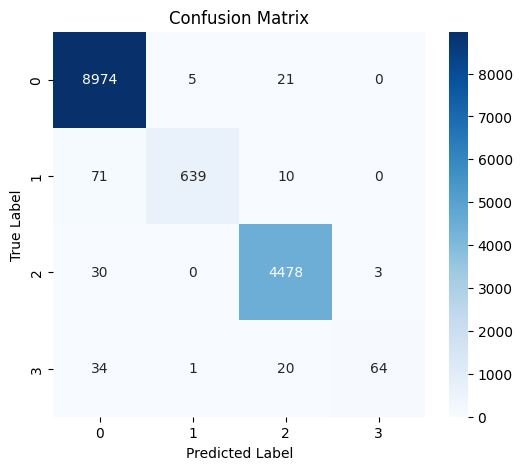

In [23]:
# baseline model run - starting with a fast RF to see where we stand
print("Training baseline Random Forest...")
model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)
print("Training complete!")

# quick eval on val set
y_pred = model.predict(X_val)
print("\n--- Classification Report ---")
print(classification_report(y_val, y_pred))

# plotting CM to see which classes get mixed up (class 3 recall might be tricky)
cm = confusion_matrix(y_val, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
# final step: infer on unlabelled test data
test_preds = model.predict(X_test)

# package up predictions into the requested format
submission = pd.DataFrame({
    'id': test_ids,
    'label': test_preds
})

# check prediction distribution to see if it makes sense
print("\nPredicted label counts:")
print(submission['label'].value_counts())

# save out to GDrive folder
submission.to_csv('/content/drive/MyDrive/nppe2_dataset/my_submission.csv', index=False)
print("\nSaved predictions to /content/drive/MyDrive/nppe2_dataset/my_submission.csv!")